<a href="https://colab.research.google.com/github/Varnika1024/DLAC/blob/main/SKILL/Skill5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install -q ultralytics pycocotools matplotlib seaborn opencv-python-headless
!mkdir -p /content/Skill5_COCO_Exploration/images
!mkdir -p /content/Skill5_COCO_Exploration/outputs
%cd /content/Skill5_COCO_Exploration

/content/Skill5_COCO_Exploration


In [15]:
from collections import Counter
import json
import urllib.request
import cv2
from pycocotools.coco import COCO

# 1. Download sample street traffic images
image_urls = {
    "indian_traffic_1.jpg": "https://ultralytics.com/images/bus.jpg",
    "indian_traffic_2.jpg": (
        "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg"
    ),
}

images_list = []
for img_id, (fname, url) in enumerate(image_urls.items(), start=1):
  path = f"images/{fname}"
  urllib.request.urlretrieve(url, path)
  img = cv2.imread(path)
  h, w, _ = img.shape
  images_list.append(
      {"id": img_id, "file_name": fname, "width": w, "height": h}
  )

# 2. Define COCO Categories (Vehicles & Pedestrians)
categories_list = [
    {"id": 1, "name": "person"},
    {"id": 2, "name": "car"},
    {"id": 3, "name": "motorcycle"},
    {"id": 4, "name": "bus"},
    {"id": 5, "name": "truck"},
    {"id": 6, "name": "auto-rickshaw"},
]

# 3. Ground-Truth COCO Bounding-Box Annotations [x_min, y_min, width, height]
annotations_list = [
    {
        "id": 1,
        "image_id": 1,
        "category_id": 4,
        "bbox": [17, 229, 785, 513],
        "area": 402705,
        "iscrowd": 0,
    },
    {
        "id": 2,
        "image_id": 1,
        "category_id": 1,
        "bbox": [48, 398, 197, 505],
        "area": 99485,
        "iscrowd": 0,
    },
    {
        "id": 3,
        "image_id": 1,
        "category_id": 1,
        "bbox": [221, 405, 123, 452],
        "area": 55596,
        "iscrowd": 0,
    },
    {
        "id": 4,
        "image_id": 1,
        "category_id": 1,
        "bbox": [669, 392, 141, 486],
        "area": 68526,
        "iscrowd": 0,
    },
    {
        "id": 5,
        "image_id": 2,
        "category_id": 4,
        "bbox": [20, 230, 780, 510],
        "area": 397800,
        "iscrowd": 0,
    },
    {
        "id": 6,
        "image_id": 2,
        "category_id": 2,
        "bbox": [540, 510, 130, 100],
        "area": 13000,
        "iscrowd": 0,
    },
    {
        "id": 7,
        "image_id": 2,
        "category_id": 3,
        "bbox": [460, 530, 70, 115],
        "area": 8050,
        "iscrowd": 0,
    },
    {
        "id": 8,
        "image_id": 2,
        "category_id": 6,
        "bbox": [310, 495, 135, 150],
        "area": 20250,
        "iscrowd": 0,
    },
]

coco_json = {
    "images": images_list,
    "categories": categories_list,
    "annotations": annotations_list,
}

with open("indian_traffic_coco.json", "w") as f:
  json.dump(coco_json, f, indent=2)

# Parse with pycocotools
coco = COCO("indian_traffic_coco.json")
print(
    f"Loaded {len(coco.getImgIds())} images, {len(coco.getCatIds())} COCO"
    f" categories, and {len(coco.getAnnIds())} bounding boxes."
)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Loaded 2 images, 6 COCO categories, and 8 bounding boxes.


Saving images (1).jpeg to images (1) (1).jpeg

=== Detections in images (1) (1).jpeg ===
  Person      : 2
  Bus         : 1
  Car         : 17
  Truck       : 0
  Motorcycle  : 6
  Bicycle     : 0
  Total Objects Detected: 26


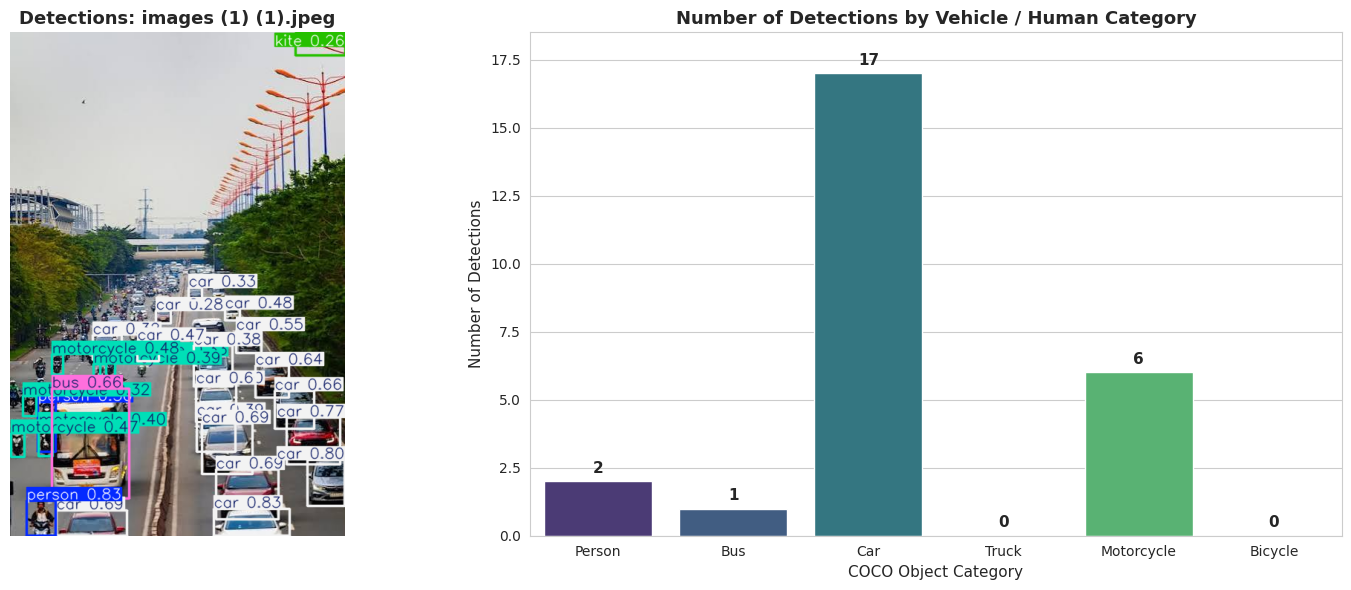

In [16]:
from collections import Counter
import cv2
from google.colab import files
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO

# 1. Open Mac file picker to upload from your Downloads folder
uploaded = files.upload()
uploaded_filename = list(uploaded.keys())[0]

# 2. Run YOLOv8n detection on your uploaded image using T4 GPU
model = YOLO("yolov8n.pt")
results = model.predict(
    source=uploaded_filename, device=0, conf=0.25, verbose=False
)[0]

# 3. Count detected objects per vehicle / pedestrian category
class_names = results.names
detected_ids = results.boxes.cls.cpu().numpy().astype(int)
counts = Counter([class_names[i] for i in detected_ids])

target_categories = ["person", "bus", "car", "truck", "motorcycle", "bicycle"]
category_labels = [cat.capitalize() for cat in target_categories]
category_values = [counts.get(cat, 0) for cat in target_categories]

print(f"\n=== Detections in {uploaded_filename} ===")
for label, val in zip(category_labels, category_values):
  print(f"  {label:<12}: {val}")
print(f"  Total Objects Detected: {sum(category_values)}")

# 4. Generate Side-by-Side Graphical Output
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Annotated Image with Bounding Boxes
annotated_rgb = cv2.cvtColor(results.plot(), cv2.COLOR_BGR2RGB)
axes[0].imshow(annotated_rgb)
axes[0].set_title(
    f"Detections: {uploaded_filename}", fontsize=13, fontweight="bold"
)
axes[0].axis("off")

# Right: Bar Chart of Vehicle / Human Counts
bars = sns.barplot(
    x=category_labels,
    y=category_values,
    ax=axes[1],
    palette="viridis",
    hue=category_labels,
    legend=False,
)
axes[1].set_title(
    "Number of Detections by Vehicle / Human Category",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("COCO Object Category", fontsize=11)
axes[1].set_ylabel("Number of Detections", fontsize=11)
axes[1].set_ylim(0, max(category_values + [1]) + 1.5)

for bar in bars.patches:
  height = int(bar.get_height())
  axes[1].annotate(
      f"{height}",
      (bar.get_x() + bar.get_width() / 2.0, height),
      ha="center",
      va="bottom",
      fontsize=11,
      fontweight="bold",
      xytext=(0, 4),
      textcoords="offset points",
  )

plt.tight_layout()
plt.savefig("outputs/custom_traffic_detections.png", dpi=150)
plt.show()

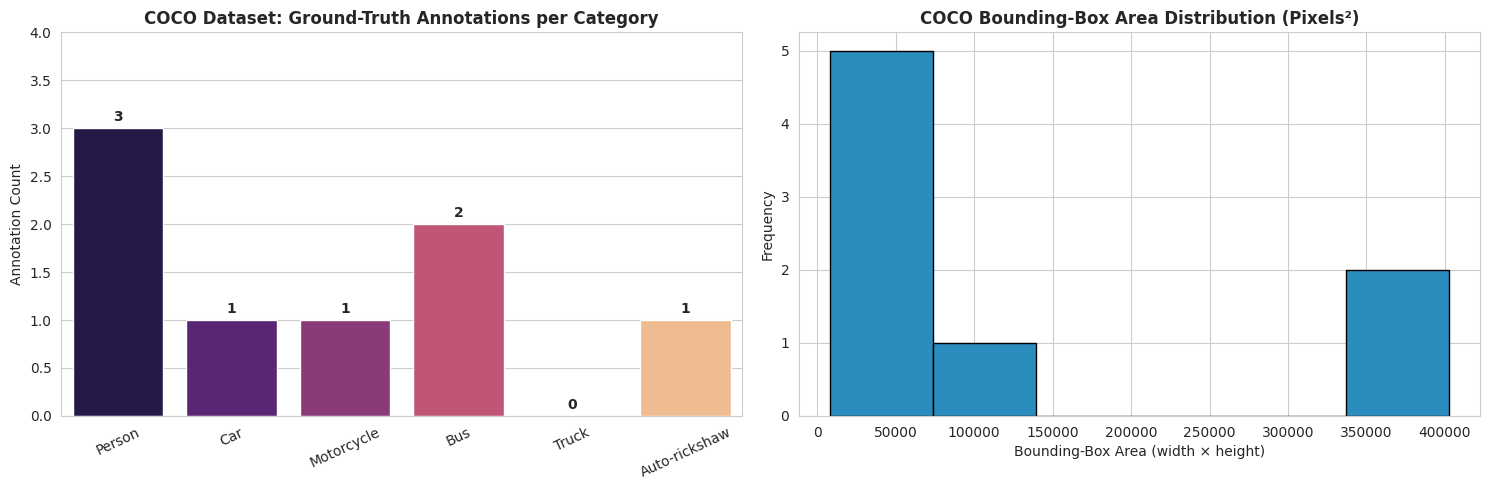

In [17]:
import matplotlib.patches as patches

# Summarize COCO Dataset Annotations across all images
cat_ids = coco.getCatIds()
cats = coco.loadCats(cat_ids)
coco_cat_names = [c["name"].capitalize() for c in cats]
coco_cat_counts = [len(coco.getAnnIds(catIds=[c["id"]])) for c in cats]

all_anns = coco.loadAnns(coco.getAnnIds())
bbox_areas = [ann["area"] for ann in all_anns]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Chart 1: Ground-Truth COCO Category Counts
bars1 = sns.barplot(
    x=coco_cat_names,
    y=coco_cat_counts,
    ax=axes[0],
    palette="magma",
    hue=coco_cat_names,
    legend=False,
)
axes[0].set_title(
    "COCO Dataset: Ground-Truth Annotations per Category",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("Annotation Count")
axes[0].set_ylim(0, max(coco_cat_counts) + 1)
axes[0].tick_params(axis="x", rotation=25)
for bar in bars1.patches:
  axes[0].annotate(
      f"{int(bar.get_height())}",
      (bar.get_x() + bar.get_width() / 2.0, bar.get_height()),
      ha="center",
      va="bottom",
      fontweight="bold",
      xytext=(0, 3),
      textcoords="offset points",
  )

# Chart 2: Bounding-Box Pixel Area Distribution
axes[1].hist(bbox_areas, bins=6, color="#2b8cbe", edgecolor="black")
axes[1].set_title(
    "COCO Bounding-Box Area Distribution (Pixels²)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Bounding-Box Area (width × height)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("outputs/coco_exploration_summary.png", dpi=150)
plt.show()